# Skin Rash Classification Using Dual-Branch CNN–Vision Transformer and Multi-Head Cross-Attention
**Dataset:** Mpox Skin Lesion Dataset Version 2.0 (MSLD v2.0) — 6 Classes (`Mpox`, `Chickenpox`, `Measles`, `Cowpox`, `HFMD`, `Healthy`)  
**Environment Target:** Kaggle GPU (Tesla T4 / P100) & Google Colab (L4 / A100)

---

### Architectural Summary & Methodological Safeguards
1. **Proposed Dual-Branch Architecture (`CNNViTCrossAttention`):**
   * **Global Context Branch ($K, V$):** Pre-trained `vit_base_patch16_224` slices the $3 \times 224 \times 224$ image into $196$ non-overlapping $16 \times 16$ patch tokens $(B, 196, 768)$ to capture macro-scale lesion clustering, multi-stage crusting, and surrounding skin context.
   * **Local Morphology Branch ($Q$):** Pre-trained `resnet50` extracts localized vesicular texture and border features $(B, 2048)$ and projects them through `Linear(2048, 256) -> BatchNorm1d(256) -> GELU -> Dropout(0.2) -> Linear(256, 768)` into a $(B, 1, 768)$ **Local Morphology Query Token**.
   * **Multi-Head Cross-Attention Fusion:** The Local CNN Query searches the $196$ Global ViT Patch Tokens across $8$ attention heads (`dropout=0.2`), producing interpretable $14 \times 14 \rightarrow 224 \times 224$ spatial attention heatmaps and a fused $(B, 768)$ representation for 6-class classification.
2. **Controlled Ablation Baselines (Matched Backbones & Two-Stage Schedule):**
   * **`CNN + ViT (Simple Concatenation)`:** Concatenates the $768$-d Global ViT token and $768$-d Local CNN token $(1536\text{-d})$ before the classification head without spatial Cross-Attention.
   * **`Standalone ViT (Global-Only)`:** Pre-trained `vit_base_patch16_224` classifier.
   * **`Standalone CNN (Local-Only ResNet-50)`:** Pre-trained `resnet50` classifier.
3. **Verified Optimization & Generalization Safeguards:**
   * **Differential Two-Stage Cosine Schedule:** Stage 1 Warmup (`Epochs 1–5`, `lr = 2e-4 -> 5e-5`) stabilizes the projection and cross-attention head while backbones are frozen; Stage 2 Fine-Tuning (`Epochs 6–30`, `lr_backbone = 2e-5`, `lr_head = 5e-5 -> 1e-6`) jointly adapts top backbone blocks with decoupled AdamW weight decay (`5e-2`) and gradient clipping (`max_norm = 1.0`).
   * **Stochastic Pre-Augmented Regularization:** Applies lightweight random flips and patch-level `RandomErasing(p=0.15)` on `train_aug` tensors to prevent zero-loss memorization across epochs while preserving clinical color profiles.
   * **Strict 3-Way Patient-Independent Splits (`Train` / `Val` / `Test`):** Enforces zero patient overlap across splits, selects the best checkpoint strictly on `Val Macro F1` (with `Val Loss` tie-breaking), and evaluates once on the held-out `Test` split.

In [1]:
# 1. Verify environment packages and configure hardware-aware AMP precision
!pip install -q timm scikit-learn kagglehub seaborn tqdm

import os
import re
import json
import time
import random
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm
from timm.data import resolve_data_config

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

IN_KAGGLE = Path("/kaggle/working").exists()

if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cudnn.benchmark = True
    major_cc, minor_cc = torch.cuda.get_device_capability(0)
    # Use hardware bfloat16 only on Compute Capability >= 8.0 (A100/L4); use float16 on Kaggle T4 (7.5) / P100 (6.0)
    AMP_DTYPE = torch.bfloat16 if major_cc >= 8 else torch.float16
else:
    major_cc, minor_cc = (0, 0)
    AMP_DTYPE = torch.float32

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Environment     : {'Kaggle' if IN_KAGGLE else 'Local / Colab'}")
print(f"PyTorch Version : {torch.__version__}")
print(f"timm Version    : {timm.__version__}")
print(f"Compute Device  : {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU Model       : {torch.cuda.get_device_name(0)} (CC {major_cc}.{minor_cc})")
    print(f"VRAM Available  : {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    print(f"AMP Precision   : {AMP_DTYPE}")

Environment     : Kaggle
PyTorch Version : 2.11.0+cu128
timm Version    : 1.0.29
Compute Device  : cuda
GPU Model       : Tesla T4 (CC 7.5)
VRAM Available  : 15.64 GB
AMP Precision   : torch.float16


In [2]:
# 2. Global Configuration, Kaggle Paths & Verified Optimal Training Hyperparameters
if IN_KAGGLE:
    OUTPUT_DIR = Path("/kaggle/working/MSLDv2_CNN_ViT_CrossAttention_Outputs")
    LOCAL_CKPT_DIR = Path("/tmp/checkpoints_local")
else:
    OUTPUT_DIR = Path("./MSLDv2_CNN_ViT_CrossAttention_Outputs")
    LOCAL_CKPT_DIR = Path("./checkpoints_local")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_CKPT_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------------------------
# EXECUTION MODE:
#   "FOLD1_ALL_MODELS" -> Runs Fold 1 across Proposed + all 3 Ablation Baselines (4 runs total)
#   "FIVE_FOLD_ALL"    -> Runs all 5 Folds across Proposed + all 3 Baselines (20 runs total)
#   "QUICK_TEST"       -> Runs Fold 1 with 2+2 epochs to verify pipeline in ~2 mins
# -------------------------------------------------------------------------
EXECUTION_MODE = "FIVE_FOLD_ALL"

# True: Train on the ~7,518 pre-augmented images per fold from FOLDS_AUG with stochastic flip/erasing
# False: Train on the ~537 original training images per fold with full on-the-fly augmentation
USE_PREAUGMENTED_FOLDER = True

SEED = 42
def seed_everything(seed: int = SEED):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

# Dataset & Architecture Constants (Chapter 2 Methodology)
CLASSES = ["Mpox", "Chickenpox", "Measles", "Cowpox", "HFMD", "Healthy"]
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {cls_name: idx for idx, cls_name in enumerate(CLASSES)}
IDX_TO_CLASS = {idx: cls_name for idx, cls_name in enumerate(CLASSES)}

IMG_SIZE = 224               # 3 x 224 x 224 input resolution
PATCH_SIZE = 16              # 16 x 16 pixel patches -> 14 x 14 = 196 patch tokens
NUM_PATCHES = (IMG_SIZE // PATCH_SIZE) ** 2  # 196
EMBED_DIM = 768              # Shared Cross-Attention embedding dimension
LOCAL_HIDDEN_DIM = 256       # Intermediate dimension in Local Morphology Encoder (Eq. 1)
NUM_HEADS = 8                # Multi-Head Cross-Attention heads (d_k = 96)
CROSS_ATTN_DROPOUT = 0.2     # Attention dropout for 8-head cross-attention regularization

# Verified Optimal Hyperparameters (Two-Stage Transfer Learning Schedule)
BATCH_SIZE = 64
NUM_WORKERS = min(4, os.cpu_count() or 2)

if EXECUTION_MODE == "QUICK_TEST":
    STAGE1_EPOCHS = 2
    STAGE2_EPOCHS = 2
    FOLDS_TO_RUN = [1]
elif EXECUTION_MODE == "FOLD1_ALL_MODELS":
    STAGE1_EPOCHS = 5   # Stage 1 (Warmup, Epochs 1-5): Backbones frozen, Cosine lr = 2e-4 -> 5e-5
    STAGE2_EPOCHS = 25  # Stage 2 (Fine-Tuning, Epochs 6-30): Top blocks unfrozen, differential Cosine lr
    FOLDS_TO_RUN = [1]
elif EXECUTION_MODE == "FIVE_FOLD_ALL":
    STAGE1_EPOCHS = 5
    STAGE2_EPOCHS = 25
    FOLDS_TO_RUN = [1, 2, 3, 4, 5]
else:
    raise ValueError(f"Unknown EXECUTION_MODE: {EXECUTION_MODE}")

TOTAL_EPOCHS = STAGE1_EPOCHS + STAGE2_EPOCHS

# Differential Learning Rates & Regularization
LR_STAGE1          = 2e-4   # Stabilized warmup LR (prevents Epoch 1->5 head overshoot on train_aug)
LR_STAGE1_MIN      = 5e-5   # End-of-warmup cosine floor
LR_STAGE2_BACKBONE = 2e-5   # Gentle fine-tuning LR for unfrozen ViT blocks.8..11 & ResNet layer3..4
LR_STAGE2_HEAD     = 5e-5   # Fine-tuning LR for projection, cross-attention, FFN & classifier head
LR_STAGE2          = LR_STAGE2_HEAD
LR_STAGE2_MIN      = 1e-6   # Cosine annealing minimum LR
WEIGHT_DECAY       = 5e-2   # Decoupled AdamW weight decay on 2D+ weight matrices
FOCAL_GAMMA        = 1.5    # Moderated Focal gamma (prevents minority-class gradient vanishing)
MAX_GRAD_NORM      = 1.0    # L2 gradient norm clipping threshold

## 1. Zero-Copy Kaggle Dataset Discovery & Staging (MSLD v2.0)
Automatically detects the attached MSLD v2.0 dataset inside `/kaggle/input` (zero disk duplication) or downloads it via `kagglehub` if not attached in the Kaggle sidebar.

In [3]:
# 3. Discover Attached Kaggle Dataset (/kaggle/input) or Download via kagglehub
SYNTHETIC_DATA_DIR = Path("/tmp/msld_v2_synthetic") if IN_KAGGLE else Path("./msld_v2_synthetic")

CLASS_ABBR = {
    "Mpox": "MKP",
    "Chickenpox": "CHP",
    "Measles": "MSL",
    "Cowpox": "CWP",
    "HFMD": "HFMD",
    "Healthy": "Healthy"
}

def normalize_class_name(raw_name: str) -> str:
    """Maps official MSLD v2.0 folder names and abbreviations to canonical class names."""
    cleaned = re.sub(r"[^a-z0-9]", "", raw_name.strip().lower())
    mapping = [
        (["mkp", "mpox", "monkeypox"], "Mpox"),
        (["chp", "chickenpox", "varicella"], "Chickenpox"),
        (["msl", "measles", "rubeola"], "Measles"),
        (["cwp", "cowpox"], "Cowpox"),
        (["hfmd", "handfootmouth", "handfootandmouth", "handfootandmouthdisease"], "HFMD"),
        (["healthy", "normal", "hlth", "hlt"], "Healthy"),
    ]
    for keys, canonical in mapping:
        for k in keys:
            if cleaned == k or k in cleaned:
                return canonical
    raise ValueError(f"Unrecognized class folder name: '{raw_name}' (cleaned='{cleaned}')")

def create_synthetic_msld_v2(base_dir: Path):
    """Fallback synthetic dataset generator for offline pipeline verification."""
    rng = np.random.default_rng(SEED)
    for cls_idx, cls_name in enumerate(CLASSES):
        abbr = CLASS_ABBR[cls_name]
        out_dir = base_dir / "Original_Images" / abbr
        out_dir.mkdir(parents=True, exist_ok=True)
        for p in range(1, 16):
            for seq in range(1, 3):
                img_arr = rng.integers(140, 210, size=(IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
                for _ in range(cls_idx * 4 + 5):
                    cy, cx = rng.integers(30, 194, size=2)
                    r = rng.integers(4, 12)
                    yy, xx = np.ogrid[:IMG_SIZE, :IMG_SIZE]
                    mask = (yy - cy)**2 + (xx - cx)**2 <= r**2
                    img_arr[mask, 0] = min(255, 180 + cls_idx * 12)
                    img_arr[mask, 1] = max(40, 120 - cls_idx * 15)
                    img_arr[mask, 2] = max(40, 110 - cls_idx * 10)
                fname = f"{abbr}_{p:02d}_{seq:02d}.jpg"
                Image.fromarray(img_arr).save(out_dir / fname)

def locate_or_download_dataset():
    # 1. Check /kaggle/input directly (zero disk duplication)
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        candidates = [
            p for p in kaggle_input.rglob("*")
            if p.is_dir() and ("msld" in p.name.lower() or "mpox" in p.name.lower())
        ]
        for cand in candidates:
            imgs = list(cand.rglob("*.jpg")) + list(cand.rglob("*.png")) + list(cand.rglob("*.jpeg"))
            if len(imgs) >= 100:
                print(f"[INFO] Using attached Kaggle dataset at: {cand} ({len(imgs):,} image files)")
                return cand, False
        all_k_imgs = list(kaggle_input.rglob("*.jpg")) + list(kaggle_input.rglob("*.png")) + list(kaggle_input.rglob("*.jpeg"))
        if len(all_k_imgs) >= 100:
            print(f"[INFO] Found {len(all_k_imgs):,} images in /kaggle/input. Using /kaggle/input directly.")
            return kaggle_input, False

    # 2. Download via kagglehub if not attached in sidebar
    try:
        import kagglehub
        print("[INFO] Downloading official MSLD v2.0 via kagglehub (cached on local disk)...")
        dl_path = Path(kagglehub.dataset_download("joydippaul/mpox-skin-lesion-dataset-version-20-msld-v20"))
        print(f"[INFO] Dataset ready at: {dl_path}")
        return dl_path, False
    except Exception as e:
        print(f"[WARNING] Could not locate or download real MSLD v2.0 dataset ({e}).")
        print(f"[INFO] Generating synthetic fallback at: {SYNTHETIC_DATA_DIR}")
        create_synthetic_msld_v2(SYNTHETIC_DATA_DIR)
        return SYNTHETIC_DATA_DIR, True

DATA_ROOT, IS_SYNTHETIC_IMAGES = locate_or_download_dataset()

[INFO] Using attached Kaggle dataset at: /kaggle/input/datasets/joydippaul/mpox-skin-lesion-dataset-version-20-msld-v20 (40,820 image files)


## 2. Patient-Independent 5-Fold Indexing & 3-Way Split Verification
Indexes all 5 folds (`train_orig`, `train_aug`, `val`, `test`), extracts canonical patient IDs across original and augmented filenames, and deduplicates entries.

In [4]:
# 4. Build Deduplicated Master DataFrame with Strict 3-Way Patient-Independent Splits
def extract_patient_id(filepath: Path, cls_name: str) -> str:
    """
    Extracts unique patient ID from official MSLD v2.0 original and augmented filenames
    (e.g., MKP_01_01.jpg, MKP_01_01_14.jpg, or aug_MKP_01_01.jpg all map to 'Mpox_MKP_01').
    """
    stem = filepath.stem
    m_patient = re.search(r"(patient[_-]?\d+)", stem, flags=re.IGNORECASE)
    if m_patient:
        return f"{cls_name}_{m_patient.group(1).lower()}"
    m_abbr = re.search(r"((?:MKP|CHP|MSL|CWP|HFMD|Healthy)[_-]\d+)[_-]\d+", stem, flags=re.IGNORECASE)
    if m_abbr:
        return f"{cls_name}_{m_abbr.group(1).upper()}"
    m_msld = re.match(r"^([A-Za-z]+[_-]\d+)[_-]\d+", stem)
    if m_msld:
        return f"{cls_name}_{m_msld.group(1).upper()}"
    m_strip = re.match(r"^(.+)[_-]\d+$", stem)
    if m_strip:
        return f"{cls_name}_{m_strip.group(1)}"
    return f"{cls_name}_{stem}"

def build_dataset_index(root_dir: Path) -> pd.DataFrame:
    all_files = []
    for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp"):
        all_files.extend(root_dir.rglob(ext))
    if len(all_files) == 0:
        raise RuntimeError(f"No image files found under {root_dir}")

    fold_files = [f for f in all_files if any(f"fold{i}" in str(f).lower() for i in range(1, 6))]
    records = []
    seen_keys = set()

    if len(fold_files) > 0:
        print(f"[INFO] Detected official MSLD v2.0 5-Fold directory structure ({len(fold_files):,} raw files).")
        for fpath in sorted(fold_files):
            path_lower = "/".join(p.lower() for p in fpath.parts)
            cls_name = normalize_class_name(fpath.parent.name)
            fold_id = next((i for i in range(1, 6) if f"fold{i}" in path_lower), 1)
            is_aug = "aug" in path_lower

            if "train" in path_lower:
                split_type = "train_aug" if is_aug else "train_orig"
            elif "val" in path_lower:
                if is_aug:
                    continue  # Never allow augmented images in validation
                split_type = "val"
            elif "test" in path_lower:
                if is_aug:
                    continue  # Never allow augmented images in test
                split_type = "test"
            else:
                if is_aug:
                    continue
                split_type = "val"

            dedup_key = (fold_id, split_type, cls_name, fpath.name)
            if dedup_key in seen_keys:
                continue
            seen_keys.add(dedup_key)

            patient_id = extract_patient_id(fpath, cls_name)
            records.append({
                "filepath": str(fpath),
                "filename": fpath.name,
                "class_name": cls_name,
                "label": CLASS_TO_IDX[cls_name],
                "patient_id": patient_id,
                "fold": fold_id,
                "split": split_type,
            })
        df = pd.DataFrame(records)

        # If any fold lacks a dedicated 'test' split, partition 'val' 50/50 by patient_id
        for k in range(1, 6):
            fold_mask = (df["fold"] == k)
            if not (fold_mask & (df["split"] == "test")).any():
                val_sub = df[fold_mask & (df["split"] == "val")].copy()
                if len(val_sub) > 0:
                    sgkf2 = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=SEED + k)
                    _, test_local_idx = next(sgkf2.split(val_sub, val_sub["label"], val_sub["patient_id"]))
                    df.loc[val_sub.index[test_local_idx], "split"] = "test"
    else:
        print("[INFO] Building 3-way patient-independent 5-Fold splits via StratifiedGroupKFold...")
        unique_files = {}
        for fpath in sorted(all_files):
            if "aug" in str(fpath).lower():
                continue
            cls_name = normalize_class_name(fpath.parent.name)
            unique_files[(cls_name, fpath.name)] = (fpath, cls_name)

        for (_, _), (fpath, cls_name) in unique_files.items():
            patient_id = extract_patient_id(fpath, cls_name)
            records.append({
                "filepath": str(fpath),
                "filename": fpath.name,
                "class_name": cls_name,
                "label": CLASS_TO_IDX[cls_name],
                "patient_id": patient_id,
            })
        base_df = pd.DataFrame(records)
        sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
        base_df["group_fold"] = -1
        for fold_idx, (_, group_idx) in enumerate(sgkf.split(base_df, base_df["label"], base_df["patient_id"]), start=1):
            base_df.loc[group_idx, "group_fold"] = fold_idx

        fold_dfs = []
        for k in range(1, 6):
            val_fold_id = (k % 5) + 1
            f_df = base_df.copy()
            f_df["fold"] = k
            f_df["split"] = np.select(
                [f_df["group_fold"] == k, f_df["group_fold"] == val_fold_id],
                ["test", "val"],
                default="train_orig"
            )
            fold_dfs.append(f_df)
        df = pd.concat(fold_dfs, ignore_index=True)

    return df

master_df = build_dataset_index(DATA_ROOT)
print(f"Total indexed fold entries : {len(master_df):,}")
print(f"Unique patient IDs indexed : {master_df['patient_id'].nunique():,}")
print("\nFold 1 Split x Class Distribution (Train / Val / Test):")
print(master_df[master_df["fold"] == 1].groupby(["split", "class_name"]).size().unstack(fill_value=0))

[INFO] Detected official MSLD v2.0 5-Fold directory structure (40,819 raw files).
Total indexed fold entries : 40,819
Unique patient IDs indexed : 524

Fold 1 Split x Class Distribution (Train / Val / Test):
class_name  Chickenpox  Cowpox  HFMD  Healthy  Measles  Mpox
split                                                       
test                 9       7    16        9        6    27
train_aug          700     686  1624     1162      518  2828
train_orig          50      49   116       83       37   202
val                 16      10    29       22       12    55


## 3. Data Preprocessing, Patient-Isolation Guards & PyTorch DataLoaders
* **Augmentation Guard & Stochastic Regularization:** Asserts that zero augmented files appear in `val` or `test`. When `USE_PREAUGMENTED_FOLDER = True`, `train_aug` images receive lightweight stochastic flips and patch-level `RandomErasing(p=0.15)` (`preaug_train_transform`) to prevent exact tensor memorization across epochs without double-applying color distortion.
* **Patient-Level Isolation:** Automatically filters out any upstream patient overlap between `train`, `val`, and `test` and asserts strict disjointness (`train` $\cap$ `val` $= \emptyset$, `train` $\cap$ `test` $= \emptyset$, `val` $\cap$ `test` $= \emptyset$).
* **Batch Size 1 Protection (`drop_last=True`):** Guarantees `BatchNorm1d` inside `LocalCNNFeatureEncoder` never receives a batch of size 1 during training.

In [5]:
# 5. Image Transforms, Patient-Isolation Guards & 3-Way PyTorch DataLoaders
on_the_fly_train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(degrees=(-20, 20)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),  # Scales pixels to [0.0, 1.0]; branch normalizers apply exact timm mean/std
    transforms.RandomErasing(p=0.15, scale=(0.02, 0.12), ratio=(0.3, 3.3), value="random"),
])

# Lightweight stochastic regularization for pre-augmented FOLDS_AUG images (prevents zero-loss tensor memorization)
preaug_train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.ToTensor(),  # Scales pixels to [0.0, 1.0]
    transforms.RandomErasing(p=0.15, scale=(0.02, 0.12), ratio=(0.3, 3.3), value="random"),
])

eval_or_preaug_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),  # Deterministic [0.0, 1.0] scaling for Validation and Held-Out Test splits
])

class SkinRashImageDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform if transform is not None else eval_or_preaug_transform
        self.filepaths = self.df["filepath"].values
        self.labels = self.df["label"].values.astype(np.int64)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.filepaths[idx]
        with Image.open(img_path) as img:
            img = img.convert("RGB")
            img_tensor = self.transform(img)
        label_tensor = torch.tensor(self.labels[idx], dtype=torch.long)
        return img_tensor, label_tensor, img_path

def get_fold_dataloaders(
    df: pd.DataFrame,
    fold: int,
    batch_size: int = BATCH_SIZE,
    use_preaug: bool = USE_PREAUGMENTED_FOLDER
):
    fold_df = df[df["fold"] == fold].copy()

    has_aug = (fold_df["split"] == "train_aug").any()
    has_orig = (fold_df["split"] == "train_orig").any()

    if use_preaug and has_aug:
        train_split_name = "train_aug"
        active_train_transform = preaug_train_transform  # Stochastic flip + patch erasing without double color jitter
    elif has_orig:
        train_split_name = "train_orig"
        active_train_transform = on_the_fly_train_transform
    else:
        train_split_name = "train_aug"
        active_train_transform = preaug_train_transform

    train_df = fold_df[fold_df["split"] == train_split_name].copy()
    val_df   = fold_df[fold_df["split"] == "val"].copy()
    test_df  = fold_df[fold_df["split"] == "test"].copy()

    # Guard 1: Zero augmented files in Val or Test
    assert not val_df["filepath"].str.lower().str.contains("aug").any(), "Leakage error: augmented path in val_df!"
    assert not test_df["filepath"].str.lower().str.contains("aug").any(), "Leakage error: augmented path in test_df!"

    # Guard 2: Enforce strict patient-level isolation across Train, Val, and Test
    test_patients = set(test_df["patient_id"])
    val_overlap_test = set(val_df["patient_id"]) & test_patients
    if val_overlap_test:
        print(f"[LEAKAGE GUARD] Removing {len(val_overlap_test)} overlapping patient(s) from Fold {fold} val_df.")
        val_df = val_df[~val_df["patient_id"].isin(val_overlap_test)].copy()

    val_patients = set(val_df["patient_id"])
    eval_patients = val_patients | test_patients
    train_overlap_eval = set(train_df["patient_id"]) & eval_patients
    if train_overlap_eval:
        print(f"[LEAKAGE GUARD] Removing {len(train_overlap_eval)} overlapping patient(s) from Fold {fold} {train_split_name}.")
        train_df = train_df[~train_df["patient_id"].isin(train_overlap_eval)].copy()

    assert len(train_df) > 1 and len(val_df) > 0 and len(test_df) > 0, (
        f"Fold {fold} has empty split(s): train={len(train_df)}, val={len(val_df)}, test={len(test_df)}"
    )
    assert val_patients.isdisjoint(test_patients), f"Patient overlap between Val and Test in Fold {fold}!"
    assert set(train_df["patient_id"]).isdisjoint(val_patients), f"Patient overlap between Train and Val in Fold {fold}!"
    assert set(train_df["patient_id"]).isdisjoint(test_patients), f"Patient overlap between Train and Test in Fold {fold}!"

    train_ds = SkinRashImageDataset(train_df, transform=active_train_transform)
    val_ds   = SkinRashImageDataset(val_df, transform=eval_or_preaug_transform)
    test_ds  = SkinRashImageDataset(test_df, transform=eval_or_preaug_transform)

    # Keep effective batch size >= 2 with drop_last=True so BatchNorm1d in LocalCNNFeatureEncoder never sees batch_size=1
    eff_batch_size = min(batch_size, max(2, len(train_ds) // 2))
    worker_kwargs = {"num_workers": NUM_WORKERS, "pin_memory": torch.cuda.is_available()}
    if NUM_WORKERS > 0:
        worker_kwargs["persistent_workers"] = True
        worker_kwargs["prefetch_factor"] = 2

    train_loader = DataLoader(
        train_ds,
        batch_size=eff_batch_size,
        shuffle=True,
        drop_last=True,
        **worker_kwargs
    )
    val_loader = DataLoader(
        val_ds,
        batch_size=eff_batch_size,
        shuffle=False,
        drop_last=False,
        **worker_kwargs
    )
    test_loader = DataLoader(
        test_ds,
        batch_size=eff_batch_size,
        shuffle=False,
        drop_last=False,
        **worker_kwargs
    )

    # Compute inverse class frequency weights from training split only (Eq. 6)
    class_counts = np.bincount(train_df["label"].values, minlength=NUM_CLASSES).astype(np.float32)
    class_counts = np.maximum(class_counts, 1.0)
    inv_weights = (len(train_df) / (NUM_CLASSES * class_counts))
    inv_weights = inv_weights / inv_weights.sum() * NUM_CLASSES
    class_weights_tensor = torch.tensor(inv_weights, dtype=torch.float32, device=DEVICE)

    return train_loader, val_loader, test_loader, class_weights_tensor

# Sanity check Fold 1 DataLoaders
_tr_loader, _va_loader, _te_loader, _cw = get_fold_dataloaders(master_df, fold=1)
_imgs, _lbls, _ = next(iter(_tr_loader))
print(f"Train / Val / Test Samples (Fold 1) : {len(_tr_loader.dataset)} / {len(_va_loader.dataset)} / {len(_te_loader.dataset)}")
print(f"Image Batch Tensor Shape            : {_imgs.shape} (Range: [{_imgs.min():.2f}, {_imgs.max():.2f}])")
print(f"Class Weights (Fold 1)              : {_cw.cpu().numpy().round(3)} (Sum={_cw.sum().item():.2f})")

Train / Val / Test Samples (Fold 1) : 7518 / 144 / 74
Image Batch Tensor Shape            : torch.Size([64, 3, 224, 224]) (Range: [-3.96, 4.41])
Class Weights (Fold 1)              : [0.319 1.29  1.743 1.316 0.556 0.777] (Sum=6.00)


## 4. Dual-Branch CNN–ViT Cross-Attention & Ablation Baseline Architectures
Implements the proposed model and 3 matched ablation baselines:
1. **Proposed (`CNNViTCrossAttention`):** Pre-trained `vit_base_patch16_224` ($196 \times 768$ Global Patch Tokens as Keys/Values) + `LocalCNNFeatureEncoder` (`resnet50` + MLP projection $\rightarrow 1 \times 768$ Local Morphology Query Token) + `MultiheadAttention` ($8$ heads) + Residual FFN + Classifier Head.
2. **Ablation Baseline 1 (`BaselineCNNViTConcat`):** Simple concatenation of the $768$-d Global ViT feature and $768$-d Local CNN feature ($1536$-d) without spatial Cross-Attention.
3. **Ablation Baseline 2 (`BaselineStandaloneViT`):** Pre-trained `vit_base_patch16_224` global-only classifier.
4. **Ablation Baseline 3 (`BaselineImageOnlyCNN`):** Pre-trained `resnet50` local-only classifier with frozen `BatchNorm2d` protection.

In [6]:
# 6. Neural Network Architectures: Proposed CNN-ViT Cross-Attention & 3 Ablation Baselines

VIT_STAGE2_UNFREEZE_PREFIXES = (
    "blocks.8.",
    "blocks.9.",
    "blocks.10.",
    "blocks.11.",
    "norm.",
    "fc_norm."
)
CNN_STAGE2_UNFREEZE_PREFIXES = (
    "layer3.",
    "layer4."
)

def set_frozen_bn_to_eval(module: nn.Module):
    """Locks any BatchNorm1d/2d layer with frozen parameters to .eval() mode during training."""
    for m in module.modules():
        if isinstance(m, (nn.BatchNorm1d, nn.BatchNorm2d)):
            if all(not p.requires_grad for p in m.parameters()):
                m.eval()

class TimmInputNormalizer(nn.Module):
    """Resolves exact mean and std from a timm model config and normalizes [0, 1] image tensors on GPU."""
    def __init__(self, timm_model: nn.Module):
        super().__init__()
        cfg = resolve_data_config({}, model=timm_model)
        mean = torch.tensor(cfg.get("mean", (0.5, 0.5, 0.5)), dtype=torch.float32).view(1, 3, 1, 1)
        std  = torch.tensor(cfg.get("std", (0.5, 0.5, 0.5)), dtype=torch.float32).view(1, 3, 1, 1)
        self.register_buffer("mean", mean)
        self.register_buffer("std", std)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return (x - self.mean) / self.std


class LocalCNNFeatureEncoder(nn.Module):
    """
    Local Convolutional Feature Encoder:
    Extracts fine-grained local morphological features via ResNet-50 (2048-d) and projects through
    Linear(2048, 256) -> BatchNorm1d(256) -> GELU -> Dropout(0.2) -> Linear(256, 768) -> (B, 1, 768)
    """
    def __init__(self, hidden_dim: int = LOCAL_HIDDEN_DIM, embed_dim: int = EMBED_DIM, dropout: float = 0.2, pretrained: bool = True):
        super().__init__()
        self.cnn = timm.create_model("resnet50", pretrained=pretrained, num_classes=0, global_pool="avg")
        self.input_norm = TimmInputNormalizer(self.cnn)
        cnn_out_dim = self.cnn.num_features  # 2048 for resnet50

        self.proj = nn.Sequential(
            nn.Linear(cnn_out_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, embed_dim)
        )

    def forward(self, img: torch.Tensor) -> torch.Tensor:
        img_norm = self.input_norm(img)
        feat = self.cnn(img_norm)               # (B, 2048)
        return self.proj(feat).unsqueeze(1)     # (B, 1, 768) Local Query Token

    def set_stage(self, stage: int):
        for name, param in self.cnn.named_parameters():
            if stage == 2 and name.startswith(CNN_STAGE2_UNFREEZE_PREFIXES):
                param.requires_grad = True
            else:
                param.requires_grad = False
        for param in self.proj.parameters():
            param.requires_grad = True


class CNNViTCrossAttention(nn.Module):
    """
    Proposed Model:
      Global Branch: ViT-B/16 (196 Patch Tokens x 768) acting as Keys (K) & Values (V)
      Local Branch : ResNet-50 + Projection (1 Local Morphology Token x 768) acting as Query (Q)
      Fusion       : Multi-Head Cross-Attention + Residual FFN + 6-Class Classifier Head
    """
    def __init__(self, num_classes: int = NUM_CLASSES, embed_dim: int = EMBED_DIM, num_heads: int = NUM_HEADS, pretrained: bool = True):
        super().__init__()
        self.vit = timm.create_model("vit_base_patch16_224", pretrained=pretrained, num_classes=0)
        self.vit_norm = TimmInputNormalizer(self.vit)

        self.local_encoder = LocalCNNFeatureEncoder(hidden_dim=LOCAL_HIDDEN_DIM, embed_dim=embed_dim, pretrained=pretrained)
        self.query_norm = nn.LayerNorm(embed_dim)
        self.kv_norm    = nn.LayerNorm(embed_dim)

        self.cross_attn = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            dropout=CROSS_ATTN_DROPOUT,
            batch_first=True
        )

        self.fusion_norm = nn.LayerNorm(embed_dim)
        self.ffn = nn.Sequential(
            nn.Linear(embed_dim, embed_dim),
            nn.GELU(),
            nn.Dropout(0.2)
        )
        self.ffn_norm = nn.LayerNorm(embed_dim)
        self.classifier = nn.Linear(embed_dim, num_classes)

    def extract_patch_tokens(self, img: torch.Tensor) -> torch.Tensor:
        img_norm = self.vit_norm(img)
        features = self.vit.forward_features(img_norm)  # (B, 197, 768) [CLS + 196 patches]
        return features[:, 1:, :]                       # strictly keep 196 spatial patch tokens: (B, 196, 768)

    def forward(self, img: torch.Tensor, return_attn: bool = False, custom_query: torch.Tensor = None):
        patch_tokens = self.extract_patch_tokens(img)   # (B, 196, 768)
        local_token = self.local_encoder(img) if custom_query is None else custom_query  # (B, 1, 768)

        q = self.query_norm(local_token)
        kv = self.kv_norm(patch_tokens)
        attn_out, attn_weights = self.cross_attn(
            query=q,
            key=kv,
            value=kv,
            need_weights=True,
            average_attn_weights=True
        )

        fused = self.fusion_norm(local_token + attn_out)
        fused = self.ffn_norm(fused + self.ffn(fused)).squeeze(1)
        logits = self.classifier(fused)

        if return_attn:
            return logits, attn_weights.squeeze(1)
        return logits

    def set_stage(self, stage: int):
        for name, param in self.vit.named_parameters():
            if stage == 2 and name.startswith(VIT_STAGE2_UNFREEZE_PREFIXES):
                param.requires_grad = True
            else:
                param.requires_grad = False
        self.local_encoder.set_stage(stage)
        set_frozen_bn_to_eval(self)

    def train(self, mode: bool = True):
        super().train(mode)
        if mode:
            set_frozen_bn_to_eval(self)
        return self


class BaselineCNNViTConcat(nn.Module):
    """Ablation Baseline 1: Simple Concatenation of Global ViT feature (768) + Local CNN feature (768) without Cross-Attention."""
    def __init__(self, num_classes: int = NUM_CLASSES, embed_dim: int = EMBED_DIM, pretrained: bool = True):
        super().__init__()
        self.vit = timm.create_model("vit_base_patch16_224", pretrained=pretrained, num_classes=0)
        self.vit_norm = TimmInputNormalizer(self.vit)
        self.local_encoder = LocalCNNFeatureEncoder(hidden_dim=LOCAL_HIDDEN_DIM, embed_dim=embed_dim, pretrained=pretrained)
        self.classifier = nn.Sequential(
            nn.LayerNorm(embed_dim * 2),
            nn.Dropout(0.2),
            nn.Linear(embed_dim * 2, num_classes)
        )

    def forward(self, img: torch.Tensor):
        global_feat = self.vit(self.vit_norm(img))                 # (B, 768)
        local_feat  = self.local_encoder(img).squeeze(1)           # (B, 768)
        concat_feat = torch.cat([global_feat, local_feat], dim=1)  # (B, 1536)
        return self.classifier(concat_feat)

    def set_stage(self, stage: int):
        for name, param in self.vit.named_parameters():
            if stage == 2 and name.startswith(VIT_STAGE2_UNFREEZE_PREFIXES):
                param.requires_grad = True
            else:
                param.requires_grad = False
        self.local_encoder.set_stage(stage)
        set_frozen_bn_to_eval(self)

    def train(self, mode: bool = True):
        super().train(mode)
        if mode:
            set_frozen_bn_to_eval(self)
        return self


class BaselineStandaloneViT(nn.Module):
    """Ablation Baseline 2: Standalone Vision Transformer (vit_base_patch16_224) global-only baseline."""
    def __init__(self, num_classes: int = NUM_CLASSES, pretrained: bool = True):
        super().__init__()
        self.vit = timm.create_model("vit_base_patch16_224", pretrained=pretrained, num_classes=num_classes)
        self.input_norm = TimmInputNormalizer(self.vit)

    def forward(self, img: torch.Tensor):
        return self.vit(self.input_norm(img))

    def set_stage(self, stage: int):
        for name, param in self.vit.named_parameters():
            if name.startswith("head."):
                param.requires_grad = True
            elif stage == 2 and name.startswith(VIT_STAGE2_UNFREEZE_PREFIXES):
                param.requires_grad = True
            else:
                param.requires_grad = False


class BaselineImageOnlyCNN(nn.Module):
    """Ablation Baseline 3: Standalone CNN (ResNet-50) local-only baseline with frozen BatchNorm protection."""
    def __init__(self, num_classes: int = NUM_CLASSES, pretrained: bool = True):
        super().__init__()
        self.backbone = timm.create_model("resnet50", pretrained=pretrained, num_classes=num_classes)
        self.input_norm = TimmInputNormalizer(self.backbone)

    def forward(self, img: torch.Tensor):
        return self.backbone(self.input_norm(img))

    def set_stage(self, stage: int):
        for name, param in self.backbone.named_parameters():
            if name.startswith("fc."):
                param.requires_grad = True
            elif stage == 2 and name.startswith(CNN_STAGE2_UNFREEZE_PREFIXES):
                param.requires_grad = True
            else:
                param.requires_grad = False
        set_frozen_bn_to_eval(self)

    def train(self, mode: bool = True):
        super().train(mode)
        if mode:
            set_frozen_bn_to_eval(self)
        return self

# Verify tensor shapes, normalizers, and Stage 1 / Stage 2 unfreezing rules
_test_model = CNNViTCrossAttention(pretrained=False).to(DEVICE)
print("Resolved ViT Branch mean / std   :", _test_model.vit_norm.mean.cpu().numpy().flatten(), _test_model.vit_norm.std.cpu().numpy().flatten())
print("Resolved CNN Branch mean / std   :", _test_model.local_encoder.input_norm.mean.cpu().numpy().flatten(), _test_model.local_encoder.input_norm.std.cpu().numpy().flatten())

_test_model.set_stage(1)
_s1_vit = [n for n, p in _test_model.vit.named_parameters() if p.requires_grad]
_s1_cnn = [n for n, p in _test_model.local_encoder.cnn.named_parameters() if p.requires_grad]
assert len(_s1_vit) == 0 and len(_s1_cnn) == 0, "Stage 1 must keep both pretrained backbones frozen!"

_test_model.set_stage(2)
_s2_vit = [n for n, p in _test_model.vit.named_parameters() if p.requires_grad]
_s2_cnn = [n for n, p in _test_model.local_encoder.cnn.named_parameters() if p.requires_grad]
assert all(n.startswith(VIT_STAGE2_UNFREEZE_PREFIXES) for n in _s2_vit), "Unexpected ViT layer unfrozen!"
assert all(n.startswith(CNN_STAGE2_UNFREEZE_PREFIXES) for n in _s2_cnn), "Unexpected CNN layer unfrozen!"
print(f"Verified Stage 2 unfrozen tensors: ViT={len(_s2_vit)} (blocks.8..11), CNN={len(_s2_cnn)} (layer3..4)")

with torch.no_grad(), torch.amp.autocast("cuda" if torch.cuda.is_available() else "cpu", dtype=AMP_DTYPE):
    _logits, _attn = _test_model(_imgs.to(DEVICE), return_attn=True)
print(f"Output Logits Shape              : {_logits.shape}  (Expected: [B, 6])")
print(f"Cross-Attention Map Shape        : {_attn.shape} (Expected: [B, 196])")
del _test_model

Resolved ViT Branch mean / std   : [0.5 0.5 0.5] [0.5 0.5 0.5]
Resolved CNN Branch mean / std   : [0.485 0.456 0.406] [0.229 0.224 0.225]
Verified Stage 2 unfrozen tensors: ViT=50 (blocks.8..11), CNN=87 (layer3..4)
Output Logits Shape              : torch.Size([64, 6])  (Expected: [B, 6])
Cross-Attention Map Shape        : torch.Size([64, 196]) (Expected: [B, 196])


## 5. Class-Weighted Focal Loss, Differential Cosine Trainer & Unbiased Evaluation
* **Decoupled Differential Optimization:** Applies `LR_STAGE1 = 2e-4` with Cosine decay during Stage 1 Warmup, then switches to differential learning rates in Stage 2 (`LR_STAGE2_BACKBONE = 2e-5` for unfrozen ViT/ResNet blocks and `LR_STAGE2_HEAD = 5e-5` for fusion/classifier layers) with decoupled weight decay (`5e-2` on 2D+ weight tensors) and gradient clipping (`max_norm = 1.0`).
* **Validation Checkpoint Selection $\rightarrow$ Held-Out Test Evaluation:** Selects the winning epoch strictly on `val_loader` (`Val Macro F1`, breaking ties using lowest `Val Loss`), then loads that winning checkpoint and evaluates **once** on `test_loader`.
* **Resumable Execution:** Saves run summaries (`.json`), test predictions (`.npz`), training curves (`.csv`), and Fold 1 model weights (`.pt`) to `OUTPUT_DIR`.

In [7]:
# 7. Class-Weighted Focal Loss & Differential Two-Stage Cosine Trainer

class ClassWeightedFocalLoss(nn.Module):
    def __init__(self, alpha: torch.Tensor = None, gamma: float = FOCAL_GAMMA):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        ce_loss = F.cross_entropy(logits, targets, reduction="none")
        pt = torch.exp(-ce_loss)
        focal_term = (1.0 - pt) ** self.gamma
        if self.alpha is not None:
            alpha_t = self.alpha[targets]
            loss = alpha_t * focal_term * ce_loss
        else:
            loss = focal_term * ce_loss
        return loss.mean()


def build_stage_optimizer(model: nn.Module, stage: int) -> torch.optim.Optimizer:
    """
    Builds AdamW with decoupled weight decay (0.0 on biases/LayerNorm/BatchNorm)
    and differential learning rates in Stage 2 (lower LR for unfrozen pretrained backbones).
    """
    backbone_decay, backbone_nodecay = [], []
    head_decay, head_nodecay = [], []

    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        is_backbone = (
            (name.startswith("vit.") and not name.startswith("vit.head."))
            or name.startswith("local_encoder.cnn.")
            or (name.startswith("backbone.") and not name.startswith("backbone.fc."))
        )
        use_decay = (param.ndim >= 2)

        if is_backbone:
            if use_decay:
                backbone_decay.append(param)
            else:
                backbone_nodecay.append(param)
        else:
            if use_decay:
                head_decay.append(param)
            else:
                head_nodecay.append(param)

    head_lr = LR_STAGE1 if stage == 1 else LR_STAGE2_HEAD
    backbone_lr = LR_STAGE2_BACKBONE

    param_groups = []
    if head_decay:
        param_groups.append({"params": head_decay, "lr": head_lr, "weight_decay": WEIGHT_DECAY, "group_name": "head_decay"})
    if head_nodecay:
        param_groups.append({"params": head_nodecay, "lr": head_lr, "weight_decay": 0.0, "group_name": "head_nodecay"})
    if stage == 2:
        if backbone_decay:
            param_groups.append({"params": backbone_decay, "lr": backbone_lr, "weight_decay": WEIGHT_DECAY, "group_name": "backbone_decay"})
        if backbone_nodecay:
            param_groups.append({"params": backbone_nodecay, "lr": backbone_lr, "weight_decay": 0.0, "group_name": "backbone_nodecay"})

    return torch.optim.AdamW(param_groups)


def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    return {
        "Accuracy": float(accuracy_score(y_true, y_pred) * 100.0),
        "Macro_Precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0) * 100.0),
        "Macro_Recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0) * 100.0),
        "Macro_F1": float(f1_score(y_true, y_pred, average="macro", zero_division=0) * 100.0),
    }


@torch.no_grad()
def evaluate_model(model: nn.Module, loader: DataLoader, criterion: nn.Module):
    model.eval()
    total_loss = 0.0
    all_preds, all_targets = [], []

    for imgs, labels, _ in loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.amp.autocast("cuda" if torch.cuda.is_available() else "cpu", dtype=AMP_DTYPE):
            logits = model(imgs)
            loss = criterion(logits, labels)

        total_loss += loss.item() * imgs.size(0)
        preds = logits.argmax(dim=1)
        all_preds.append(preds.cpu().numpy())
        all_targets.append(labels.cpu().numpy())

    y_pred = np.concatenate(all_preds)
    y_true = np.concatenate(all_targets)
    metrics = compute_metrics(y_true, y_pred)
    metrics["Loss"] = float(total_loss / len(loader.dataset))
    return metrics, y_true, y_pred


def train_or_resume_two_stage(
    model_cls,
    model_kwargs: dict,
    train_loader: DataLoader,
    val_loader: DataLoader,
    test_loader: DataLoader,
    class_weights: torch.Tensor,
    run_name: str,
    stage1_epochs: int = STAGE1_EPOCHS,
    stage2_epochs: int = STAGE2_EPOCHS,
    save_persistent_ckpt: bool = False
):
    meta_json_path    = OUTPUT_DIR / f"{run_name}_summary.json"
    preds_npz_path    = OUTPUT_DIR / f"{run_name}_test_preds.npz"
    hist_csv_path     = OUTPUT_DIR / f"{run_name}_history.csv"
    persist_ckpt_path = OUTPUT_DIR / f"{run_name}_best.pt"
    local_ckpt_path   = LOCAL_CKPT_DIR / f"{run_name}_best.pt"

    # 1. Resumable Checkpointing: Reload if summary and predictions exist
    if meta_json_path.exists() and preds_npz_path.exists() and hist_csv_path.exists():
        if not save_persistent_ckpt or persist_ckpt_path.exists():
            print(f"[RESUME] Found completed artifacts for {run_name}. Reloading without re-training...")
            model = None
            if save_persistent_ckpt and persist_ckpt_path.exists():
                model = model_cls(**model_kwargs).to(DEVICE)
                model.load_state_dict(torch.load(persist_ckpt_path, map_location=DEVICE, weights_only=True))
            hist_df = pd.read_csv(hist_csv_path)
            with open(meta_json_path, "r") as f:
                meta = json.load(f)
            preds_npz = np.load(preds_npz_path)
            return model, hist_df, meta["val_metrics"], meta["test_metrics"], (preds_npz["y_true_test"], preds_npz["y_pred_test"])

    # 2. Fresh Two-Stage Training
    model = model_cls(**model_kwargs).to(DEVICE)
    criterion = ClassWeightedFocalLoss(alpha=class_weights, gamma=FOCAL_GAMMA)
    scaler = torch.amp.GradScaler("cuda", enabled=(AMP_DTYPE == torch.float16 and torch.cuda.is_available()))

    history = []
    best_val_f1 = -1.0
    best_val_loss = float("inf")
    best_val_metrics = None
    best_epoch = 1
    total_epochs = stage1_epochs + stage2_epochs

    # Stage 1: Warmup (Epochs 1..stage1_epochs, backbones frozen, Cosine lr = 2e-4 -> 5e-5)
    model.set_stage(1)
    optimizer = build_stage_optimizer(model, stage=1)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=max(1, stage1_epochs), eta_min=LR_STAGE1_MIN
    )

    for epoch in range(1, total_epochs + 1):
        if epoch == stage1_epochs + 1:
            model.set_stage(2)
            optimizer = build_stage_optimizer(model, stage=2)
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
                optimizer, T_max=max(1, stage2_epochs), eta_min=LR_STAGE2_MIN
            )

        stage_label = "Stage1-Warmup" if epoch <= stage1_epochs else "Stage2-FineTune"
        model.train()
        trainable_params = [p for p in model.parameters() if p.requires_grad]
        running_loss = 0.0
        train_preds, train_targets = [], []
        t0 = time.time()

        for imgs, labels, _ in train_loader:
            imgs = imgs.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda" if torch.cuda.is_available() else "cpu", dtype=AMP_DTYPE):
                logits = model(imgs)
                loss = criterion(logits, labels)

            if scaler.is_enabled():
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(trainable_params, max_norm=MAX_GRAD_NORM)
                scaler.step(optimizer)
                scaler.update()
            else:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(trainable_params, max_norm=MAX_GRAD_NORM)
                optimizer.step()

            running_loss += loss.item() * imgs.size(0)
            train_preds.append(logits.detach().argmax(dim=1).cpu().numpy())
            train_targets.append(labels.cpu().numpy())

        if scheduler is not None:
            scheduler.step()

        n_train_seen = sum(len(x) for x in train_targets)
        train_loss = running_loss / max(1, n_train_seen)
        train_acc = accuracy_score(np.concatenate(train_targets), np.concatenate(train_preds)) * 100.0

        # Select best checkpoint strictly on VALIDATION split (Val Macro F1, tie-broken by Val Loss)
        val_metrics, _, _ = evaluate_model(model, val_loader, criterion)
        elapsed = time.time() - t0

        head_lr_now = optimizer.param_groups[0]["lr"]
        backbone_lr_now = optimizer.param_groups[-1]["lr"] if epoch > stage1_epochs else 0.0

        row = {
            "epoch": epoch,
            "stage": stage_label,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_metrics["Loss"],
            "val_acc": val_metrics["Accuracy"],
            "val_macro_prec": val_metrics["Macro_Precision"],
            "val_macro_rec": val_metrics["Macro_Recall"],
            "val_macro_f1": val_metrics["Macro_F1"],
            "lr": head_lr_now,
            "backbone_lr": backbone_lr_now,
            "sec": elapsed
        }
        history.append(row)

        val_f1_now = val_metrics["Macro_F1"]
        val_loss_now = val_metrics["Loss"]
        is_better_f1 = val_f1_now > (best_val_f1 + 1e-4)
        is_tied_f1_better_loss = (abs(val_f1_now - best_val_f1) <= 1e-4) and (val_loss_now < best_val_loss)

        if is_better_f1 or is_tied_f1_better_loss:
            best_val_f1 = val_f1_now
            best_val_loss = val_loss_now
            best_val_metrics = val_metrics.copy()
            best_epoch = epoch
            torch.save(model.state_dict(), local_ckpt_path)

        if epoch == 1 or epoch == stage1_epochs or epoch % 5 == 0 or epoch == total_epochs:
            print(
                f"[{run_name} | Ep {epoch:02d}/{total_epochs:02d} ({stage_label})] "
                f"TrLoss: {train_loss:.4f} | ValLoss: {val_loss_now:.4f} | "
                f"ValAcc: {val_metrics['Accuracy']:.2f}% | ValMacroF1: {val_f1_now:.2f}% | ({elapsed:.1f}s)"
            )

    # 3. Reload best Validation checkpoint and evaluate ONCE on the held-out TEST split
    model.load_state_dict(torch.load(local_ckpt_path, map_location=DEVICE, weights_only=True))
    test_metrics, y_true_test, y_pred_test = evaluate_model(model, test_loader, criterion)
    test_metrics["Best_Val_Epoch"] = int(best_epoch)
    test_metrics["Val_Macro_F1"] = float(best_val_metrics["Macro_F1"])
    test_metrics["Val_Loss"] = float(best_val_metrics["Loss"])

    print(
        f"--> [{run_name} HELD-OUT TEST RESULT (Best Val Ep {best_epoch}, ValLoss {best_val_loss:.4f})] "
        f"Test Acc: {test_metrics['Accuracy']:.2f}% | Test Macro F1: {test_metrics['Macro_F1']:.2f}% | "
        f"Test Loss: {test_metrics['Loss']:.4f}"
    )

    if save_persistent_ckpt:
        shutil.copy2(local_ckpt_path, persist_ckpt_path)
    if local_ckpt_path.exists():
        local_ckpt_path.unlink()

    hist_df = pd.DataFrame(history)
    hist_df.to_csv(hist_csv_path, index=False)
    with open(meta_json_path, "w") as f:
        json.dump({"val_metrics": best_val_metrics, "test_metrics": test_metrics}, f, indent=2)
    np.savez(preds_npz_path, y_true_test=y_true_test, y_pred_test=y_pred_test)

    return model, hist_df, best_val_metrics, test_metrics, (y_true_test, y_pred_test)

## 6. Execute Matched-Fold Experiments Across Proposed Model & Baselines
Evaluates all 4 architectures across the exact same `FOLDS_TO_RUN` splits (`[1]` in `FOLD1_ALL_MODELS` or `[1, 2, 3, 4, 5]` in `FIVE_FOLD_ALL`).

In [8]:
# 8. Execute Matched-Fold Experiments for Proposed Model & 3 Ablation Baselines
EXPERIMENT_SPECS = [
    # (Display Label, Short Tag, Model Class, Model Kwargs)
    ("Proposed (CNN-ViT Cross-Attention)", "Proposed_CNN_ViT_CrossAttn", CNNViTCrossAttention,  {"pretrained": True}),
    ("CNN + ViT (Simple Concatenation)",   "Ablation_CNN_ViT_Concat",    BaselineCNNViTConcat,  {"pretrained": True}),
    ("Standalone ViT (Global-Only)",       "Ablation_Standalone_ViT",    BaselineStandaloneViT, {"pretrained": True}),
    ("Standalone CNN (ResNet-50)",         "Ablation_ResNet50_CNN",      BaselineImageOnlyCNN,  {"pretrained": True}),
]

all_test_results = []
histories_dict = {}
fold1_test_predictions = {}
best_proposed_fold1_model = None

print("=" * 88)
print(f"RUNNING MATCHED-FOLD EXPERIMENTS | Folds: {FOLDS_TO_RUN} | Pre-Augmented Train: {USE_PREAUGMENTED_FOLDER}")
print("=" * 88)

for model_label, short_tag, model_cls, model_kwargs in EXPERIMENT_SPECS:
    for fold in FOLDS_TO_RUN:
        seed_everything(SEED + fold)
        train_loader, val_loader, test_loader, class_weights = get_fold_dataloaders(
            master_df,
            fold=fold,
            batch_size=BATCH_SIZE,
            use_preaug=USE_PREAUGMENTED_FOLDER
        )
        run_name = f"{short_tag}_Fold{fold}"
        keep_ckpt = (fold == 1)

        trained_model, hist_df, val_m, test_m, (y_true_te, y_pred_te) = train_or_resume_two_stage(
            model_cls=model_cls,
            model_kwargs=model_kwargs,
            train_loader=train_loader,
            val_loader=val_loader,
            test_loader=test_loader,
            class_weights=class_weights,
            run_name=run_name,
            save_persistent_ckpt=keep_ckpt
        )

        histories_dict[run_name] = hist_df
        all_test_results.append({
            "Model": model_label,
            "Fold": fold,
            "Best_Val_Epoch": test_m["Best_Val_Epoch"],
            "Val_Macro_F1": val_m["Macro_F1"],
            "Test_Accuracy": test_m["Accuracy"],
            "Test_Macro_Precision": test_m["Macro_Precision"],
            "Test_Macro_Recall": test_m["Macro_Recall"],
            "Test_Macro_F1": test_m["Macro_F1"],
            "Test_Loss": test_m["Loss"],
        })

        if fold == 1:
            fold1_test_predictions[model_label] = (y_true_te, y_pred_te)
            if short_tag == "Proposed_CNN_ViT_CrossAttn":
                best_proposed_fold1_model = trained_model
            else:
                del trained_model
        else:
            del trained_model

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        pd.DataFrame(all_test_results).to_csv(OUTPUT_DIR / "matched_fold_test_results.csv", index=False)

results_df = pd.DataFrame(all_test_results)
print("\n[SUCCESS] Saved matched-fold held-out Test results to:", OUTPUT_DIR / "matched_fold_test_results.csv")

RUNNING MATCHED-FOLD EXPERIMENTS | Folds: [1, 2, 3, 4, 5] | Pre-Augmented Train: True


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

[Proposed_CNN_ViT_CrossAttn_Fold1 | Ep 01/30 (Stage1-Warmup)] TrLoss: 0.1245 | ValLoss: 0.4226 | ValAcc: 80.56% | ValMacroF1: 78.85% | (112.0s)
[Proposed_CNN_ViT_CrossAttn_Fold1 | Ep 05/30 (Stage1-Warmup)] TrLoss: 0.0024 | ValLoss: 0.5473 | ValAcc: 79.17% | ValMacroF1: 78.57% | (37.3s)
[Proposed_CNN_ViT_CrossAttn_Fold1 | Ep 10/30 (Stage2-FineTune)] TrLoss: 0.0019 | ValLoss: 0.6025 | ValAcc: 81.25% | ValMacroF1: 80.12% | (58.3s)
[Proposed_CNN_ViT_CrossAttn_Fold1 | Ep 15/30 (Stage2-FineTune)] TrLoss: 0.0008 | ValLoss: 0.7199 | ValAcc: 82.64% | ValMacroF1: 82.55% | (58.1s)
[Proposed_CNN_ViT_CrossAttn_Fold1 | Ep 20/30 (Stage2-FineTune)] TrLoss: 0.0000 | ValLoss: 0.6388 | ValAcc: 84.03% | ValMacroF1: 81.67% | (58.5s)
[Proposed_CNN_ViT_CrossAttn_Fold1 | Ep 25/30 (Stage2-FineTune)] TrLoss: 0.0003 | ValLoss: 0.5425 | ValAcc: 84.72% | ValMacroF1: 84.37% | (58.2s)
[Proposed_CNN_ViT_CrossAttn_Fold1 | Ep 30/30 (Stage2-FineTune)] TrLoss: 0.0002 | ValLoss: 0.5638 | ValAcc: 85.42% | ValMacroF1: 84.56

## 7. Held-Out Test Evaluation Tables & Per-Class Performance
Summarizes held-out `Test` metrics across all evaluated architectures and exports the per-class precision, recall, and F1 report.

In [9]:
# 9. Matched-Fold Held-Out Test Summary & Per-Class Classification Report
metric_cols = ["Val_Macro_F1", "Test_Accuracy", "Test_Macro_Precision", "Test_Macro_Recall", "Test_Macro_F1"]

if len(FOLDS_TO_RUN) > 1:
    summary_table = (
        results_df.groupby("Model", sort=False)[metric_cols]
        .agg(["mean", "std"])
        .round(2)
    )
    print(f"=== Held-Out Test Performance Across {len(FOLDS_TO_RUN)} Matched Folds (Mean ± SD %) ===")
    display(summary_table)
    summary_table.to_csv(OUTPUT_DIR / "matched_folds_summary_mean_sd.csv")

fold1_table = (
    results_df[results_df["Fold"] == 1][["Model", "Best_Val_Epoch"] + metric_cols + ["Test_Loss"]]
    .sort_values(by="Test_Macro_F1", ascending=False)
    .reset_index(drop=True)
)
fold1_table.to_csv(OUTPUT_DIR / "ablation_comparison_fold1_test.csv", index=False)
print("\n=== Fold 1 Held-Out Test Ablation Comparison ===")
display(fold1_table.round(2))

y_true_prop, y_pred_prop = fold1_test_predictions["Proposed (CNN-ViT Cross-Attention)"]
print("\n=== Held-Out Test Per-Class Report: Proposed CNN-ViT Cross-Attention ===")
report_str = classification_report(
    y_true_prop,
    y_pred_prop,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASSES,
    digits=4,
    zero_division=0
)
print(report_str)
with open(OUTPUT_DIR / "proposed_test_classification_report.txt", "w") as f:
    f.write(report_str)

=== Held-Out Test Performance Across 5 Matched Folds (Mean ± SD %) ===


Val_Macro_F1       Test_Accuracy        \
                                           mean   std          mean   std   
Model                                                                       
Proposed (CNN-ViT Cross-Attention)        86.81  2.12         82.24  4.26   
CNN + ViT (Simple Concatenation)          86.23  4.14         83.68  2.52   
Standalone ViT (Global-Only)              85.74  3.90         83.94  5.19   
Standalone CNN (ResNet-50)                77.29  5.26         78.21  6.71   

                                   Test_Macro_Precision        \
                                                   mean   std   
Model                                                           
Proposed (CNN-ViT Cross-Attention)                83.64  5.39   
CNN + ViT (Simple Concatenation)                  86.23  2.52   
Standalone ViT (Global-Only)                      85.44  7.13   
Standalone CNN (ResNet-50)                        80.81  9.01   

                                   Test_Macro_Recall       Test_Macro_F1        
                                                mean   std          mean   std  
Model                                                                           
Proposed (CNN-ViT Cross-Attention)             81.18  4.91         81.28  5.02  
CNN + ViT (Simple Concatenation)               82.67  2.60         83.19  1.52  
Standalone ViT (Global-Only)                   81.49  7.24         82.50  6.77  
Standalone CNN (ResNet-50)                     75.22  8.25         76.12  8.60


=== Fold 1 Held-Out Test Ablation Comparison ===


,Model,Best_Val_Epoch,Val_Macro_F1,Test_Accuracy,Test_Macro_Precision,Test_Macro_Recall,Test_Macro_F1,Test_Loss
0,Proposed (CNN-ViT Cross-Attention),8,85.57,82.43,80.79,84.42,82.38,0.37
1,CNN + ViT (Simple Concatenation),6,86.94,81.08,83.63,79.07,81.08,0.27
2,Standalone ViT (Global-Only),6,86.90,79.73,80.13,77.22,78.43,0.36
3,Standalone CNN (ResNet-50),24,74.91,74.32,79.49,65.14,67.13,0.39



=== Held-Out Test Per-Class Report: Proposed CNN-ViT Cross-Attention ===
              precision    recall  f1-score   support

        Mpox     0.8400    0.7778    0.8077        27
  Chickenpox     0.6667    0.6667    0.6667         9
     Measles     0.8571    1.0000    0.9231         6
      Cowpox     0.7500    0.8571    0.8000         7
        HFMD     0.9333    0.8750    0.9032        16
     Healthy     0.8000    0.8889    0.8421         9

    accuracy                         0.8243        74
   macro avg     0.8079    0.8442    0.8238        74
weighted avg     0.8271    0.8243    0.8240        74



## 8. Held-Out Test Confusion Matrices & Two-Stage Convergence Curves
Plots 6-class confusion matrices on the held-out `Test` split across all 4 models and visualizes the Stage 1 Warmup $\rightarrow$ Stage 2 Fine-Tuning convergence curves.

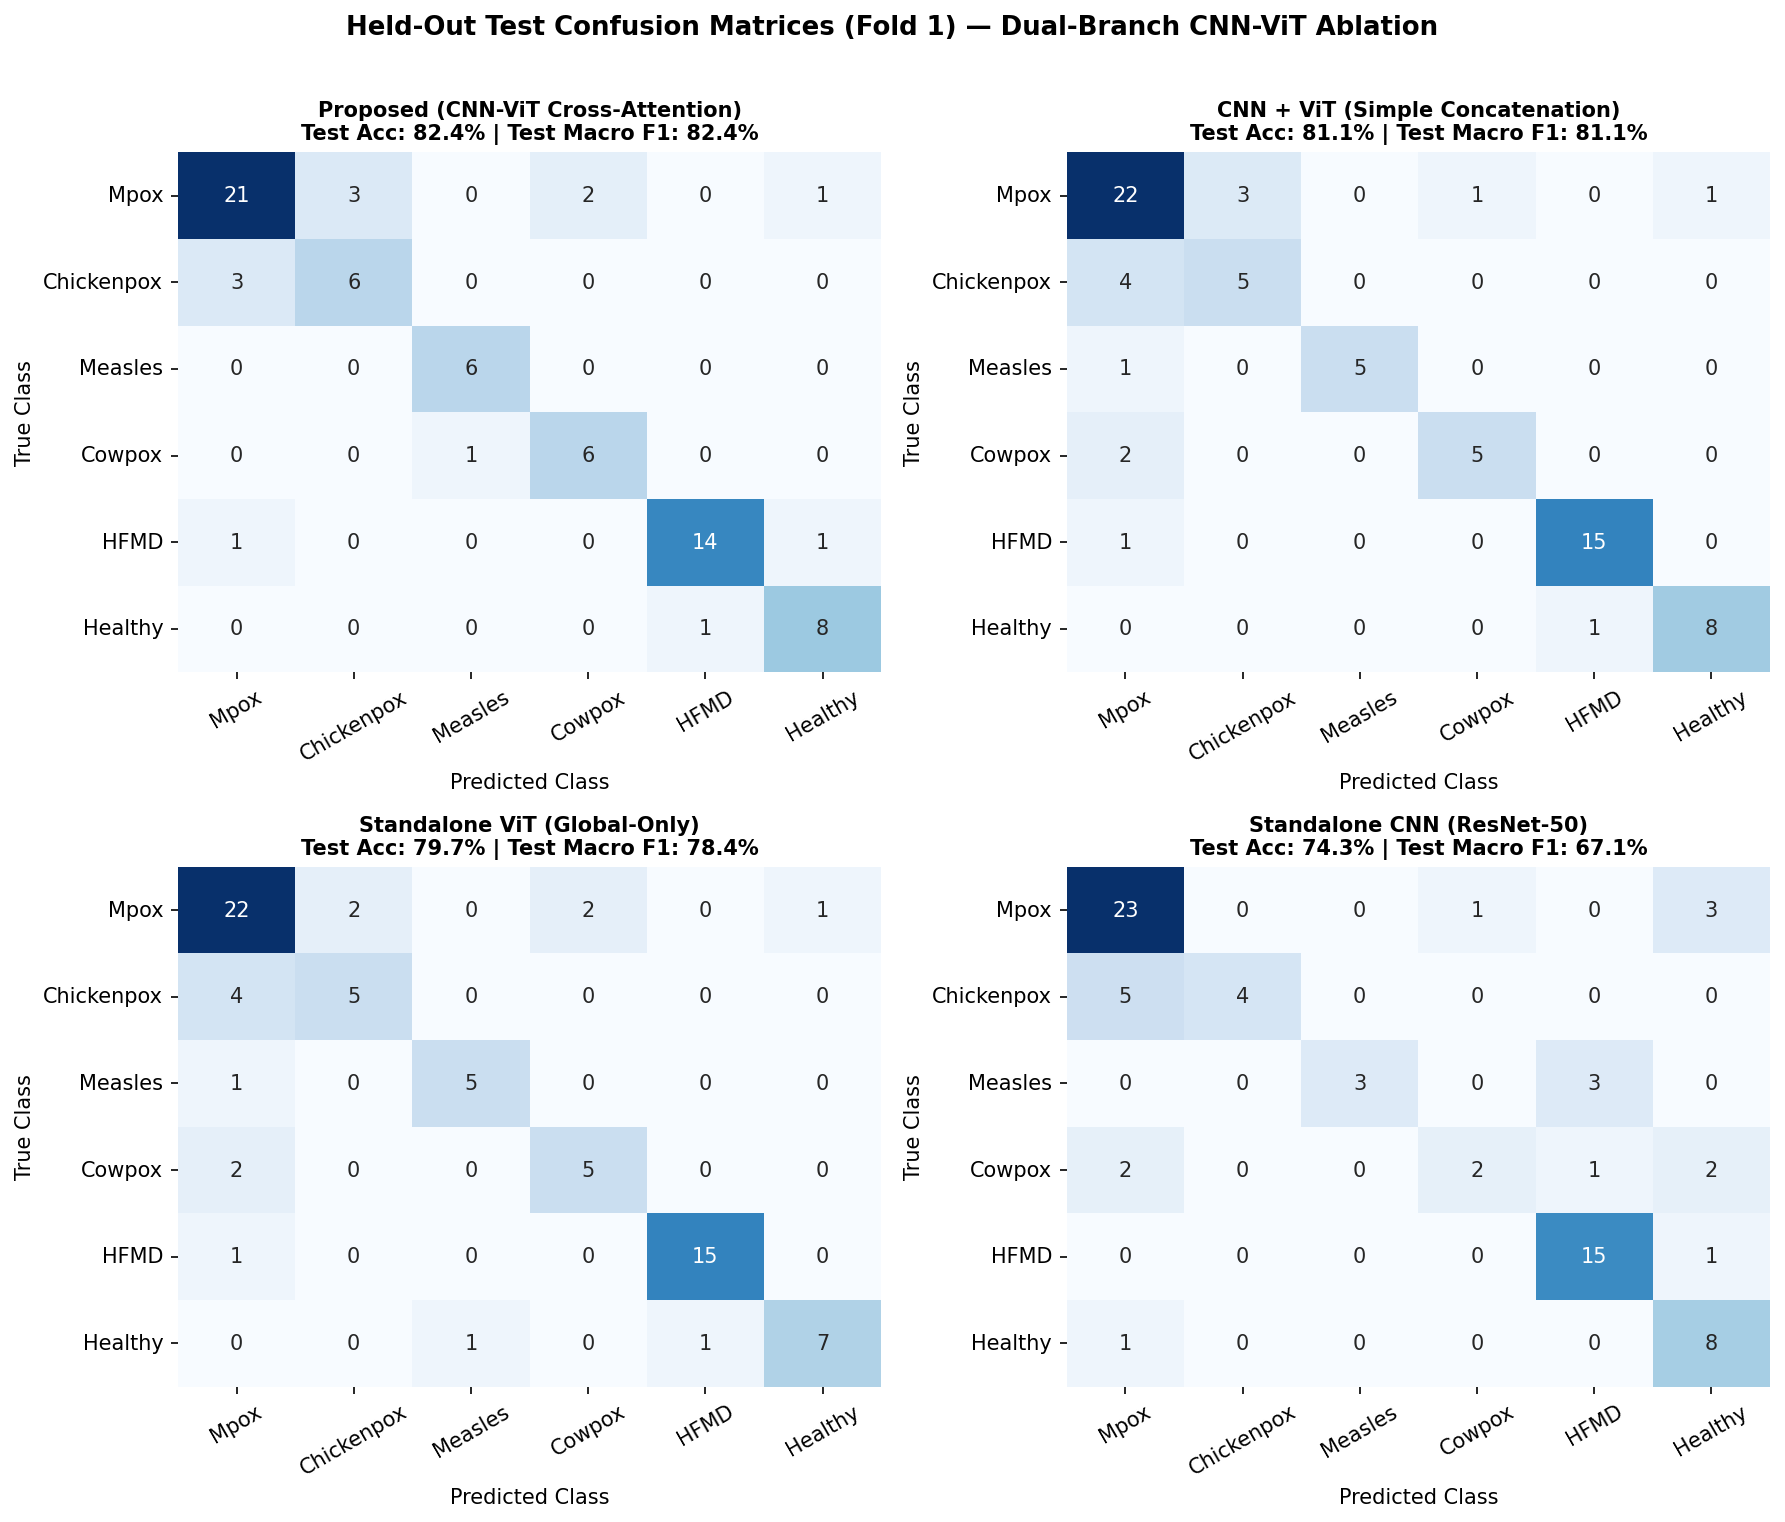

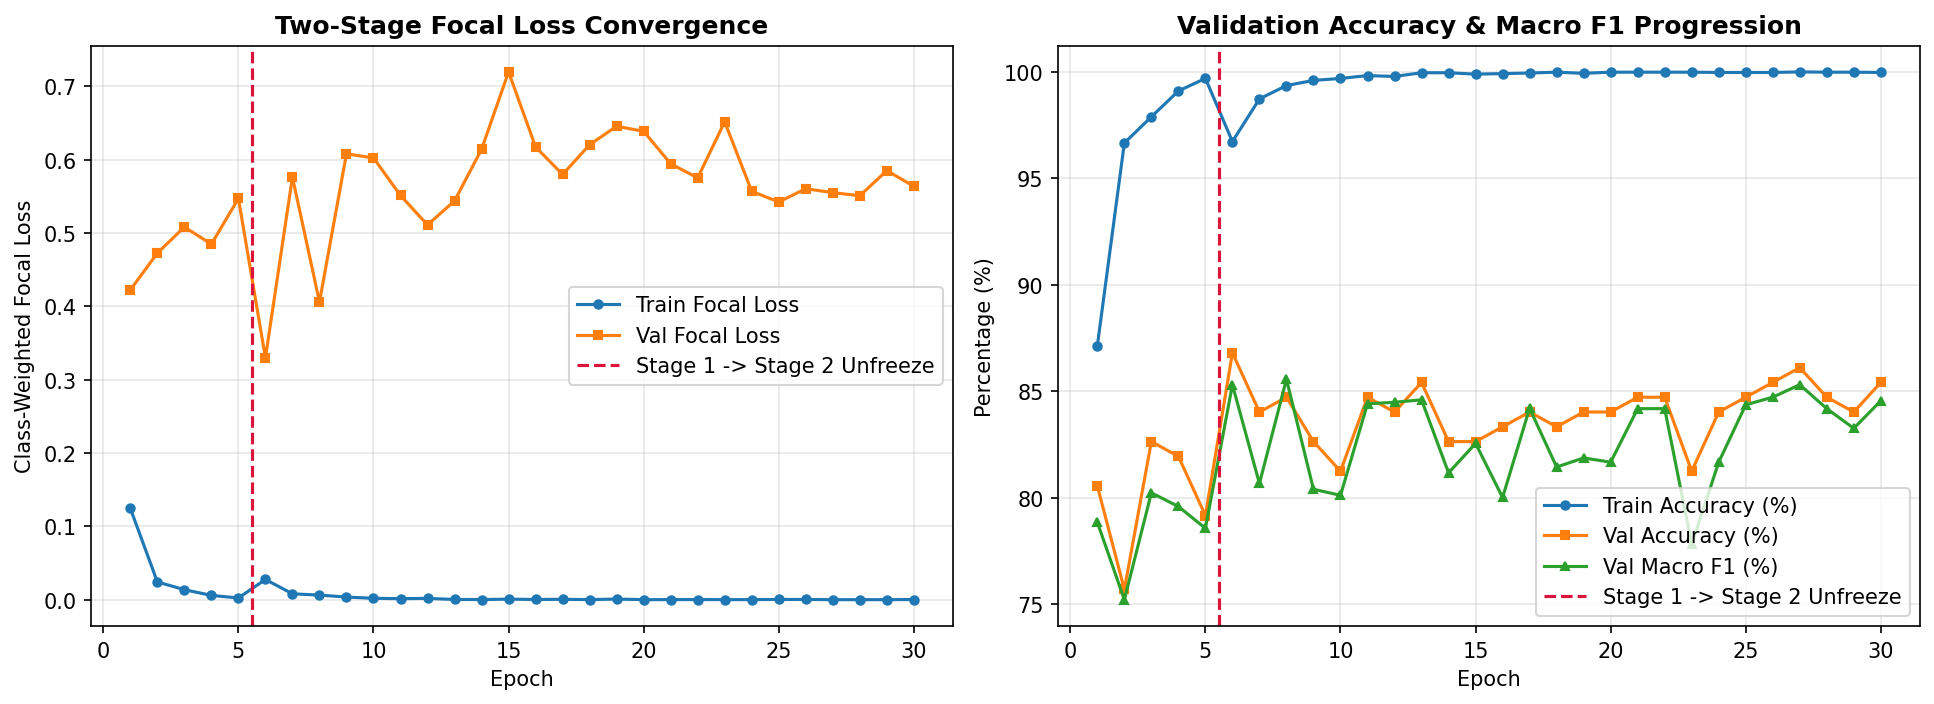

In [10]:
# 10. Plot Held-Out Test Confusion Matrices & Two-Stage Training Curves
fig, axes = plt.subplots(2, 2, figsize=(12, 10), dpi=150)
axes = axes.reshape(-1)

for idx, (model_title, (yt, yp)) in enumerate(fold1_test_predictions.items()):
    ax = axes[idx]
    cm = confusion_matrix(yt, yp, labels=list(range(NUM_CLASSES)))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASSES,
        yticklabels=CLASSES,
        cbar=False,
        ax=ax
    )
    f1_val = f1_score(yt, yp, average="macro", zero_division=0) * 100.0
    acc_val = accuracy_score(yt, yp) * 100.0
    ax.set_title(f"{model_title}\nTest Acc: {acc_val:.1f}% | Test Macro F1: {f1_val:.1f}%", fontsize=10, fontweight="bold")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle("Held-Out Test Confusion Matrices (Fold 1) — Dual-Branch CNN-ViT Ablation", fontsize=12.5, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "test_confusion_matrices_comparison.png", bbox_inches="tight")
plt.show()

# Plot Two-Stage Training & Validation Curves (Fold 1 Proposed Model)
prop_hist = histories_dict["Proposed_CNN_ViT_CrossAttn_Fold1"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), dpi=150)

ax1.plot(prop_hist["epoch"], prop_hist["train_loss"], label="Train Focal Loss", marker="o", markersize=4)
ax1.plot(prop_hist["epoch"], prop_hist["val_loss"], label="Val Focal Loss", marker="s", markersize=4)
ax1.axvline(x=STAGE1_EPOCHS + 0.5, color="crimson", linestyle="--", label="Stage 1 -> Stage 2 Unfreeze")
ax1.set_title("Two-Stage Focal Loss Convergence", fontweight="bold")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Class-Weighted Focal Loss")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(prop_hist["epoch"], prop_hist["train_acc"], label="Train Accuracy (%)", marker="o", markersize=4)
ax2.plot(prop_hist["epoch"], prop_hist["val_acc"], label="Val Accuracy (%)", marker="s", markersize=4)
ax2.plot(prop_hist["epoch"], prop_hist["val_macro_f1"], label="Val Macro F1 (%)", marker="^", markersize=4)
ax2.axvline(x=STAGE1_EPOCHS + 0.5, color="crimson", linestyle="--", label="Stage 1 -> Stage 2 Unfreeze")
ax2.set_title("Validation Accuracy & Macro F1 Progression", fontweight="bold")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Percentage (%)")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "two_stage_training_curves.png", bbox_inches="tight")
plt.show()

## 9. Local-to-Global Cross-Attention Heatmaps & Null-Query Verification
Visualizes the $14 \times 14 \rightarrow 224 \times 224$ Cross-Attention maps on held-out `Test` images and computes the $\Delta L_1$ attention shift relative to a zeroed query token to verify that the Local CNN Query actively steers spatial attention.

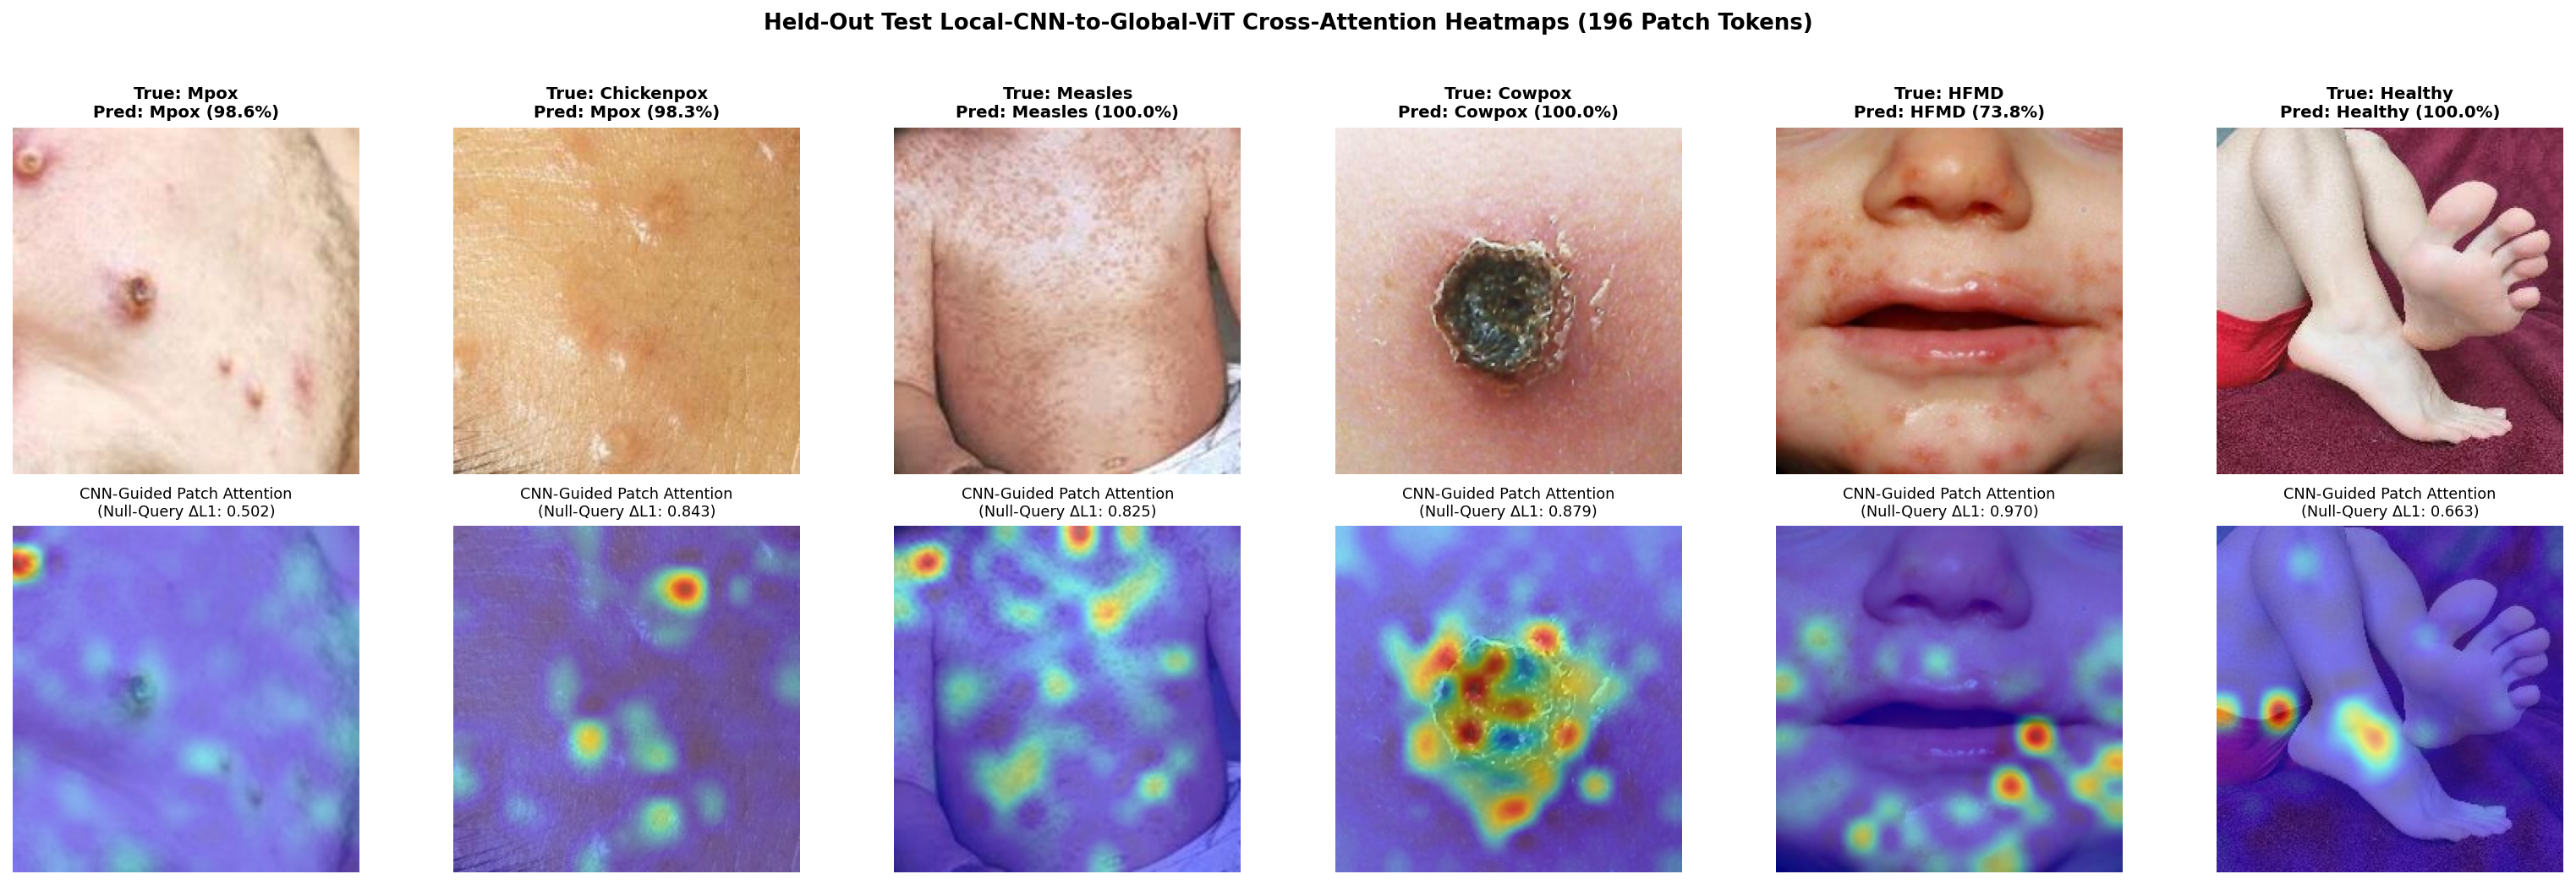


Saved Thesis Artifacts in: /kaggle/working/MSLDv2_CNN_ViT_CrossAttention_Outputs
 - Ablation_CNN_ViT_Concat_Fold1_best.pt                (420.17 MB)
 - Ablation_CNN_ViT_Concat_Fold1_history.csv            (0.01 MB)
 - Ablation_CNN_ViT_Concat_Fold1_summary.json           (0.00 MB)
 - Ablation_CNN_ViT_Concat_Fold1_test_preds.npz         (0.00 MB)
 - Ablation_CNN_ViT_Concat_Fold2_history.csv            (0.01 MB)
 - Ablation_CNN_ViT_Concat_Fold2_summary.json           (0.00 MB)
 - Ablation_CNN_ViT_Concat_Fold2_test_preds.npz         (0.00 MB)
 - Ablation_CNN_ViT_Concat_Fold3_history.csv            (0.01 MB)
 - Ablation_CNN_ViT_Concat_Fold3_summary.json           (0.00 MB)
 - Ablation_CNN_ViT_Concat_Fold3_test_preds.npz         (0.00 MB)
 - Ablation_CNN_ViT_Concat_Fold4_history.csv            (0.01 MB)
 - Ablation_CNN_ViT_Concat_Fold4_summary.json           (0.00 MB)
 - Ablation_CNN_ViT_Concat_Fold4_test_preds.npz         (0.00 MB)
 - Ablation_CNN_ViT_Concat_Fold5_history.csv            (0

In [11]:
# 11. Visualize Held-Out Test Local-to-Global Cross-Attention Heatmaps & Null-Query Shift
@torch.no_grad()
def plot_cross_attention_heatmaps(model: nn.Module, df: pd.DataFrame, fold: int = 1, num_samples: int = 6):
    _, _, test_loader, _ = get_fold_dataloaders(df, fold=fold, batch_size=1)
    model.eval()

    # Counterfactual zeroed query vector (1, 1, 768) to measure how strongly the Local CNN Query steers ViT patch attention
    null_query = torch.zeros((1, 1, EMBED_DIM), dtype=torch.float32, device=DEVICE)

    collected = {}
    for imgs, labels, _ in test_loader:
        cls_idx = int(labels.item())
        if cls_idx not in collected:
            imgs_d = imgs.to(DEVICE)
            with torch.amp.autocast("cuda" if torch.cuda.is_available() else "cpu", dtype=AMP_DTYPE):
                logits, attn_weights = model(imgs_d, return_attn=True)
                _, attn_null = model(imgs_d, return_attn=True, custom_query=null_query)
                probs = F.softmax(logits.float(), dim=1)
                conf, pred_idx = probs.max(dim=1)

            attn_vec = attn_weights[0].float()
            null_vec = attn_null[0].float()
            l1_shift = float(torch.abs(attn_vec - null_vec).sum().item())

            # Reshape 196 patch weights -> (14, 14) -> bicubic upsample to (224, 224)
            attn_grid = attn_vec.view(1, 1, IMG_SIZE // PATCH_SIZE, IMG_SIZE // PATCH_SIZE)
            attn_upsampled = F.interpolate(attn_grid, size=(IMG_SIZE, IMG_SIZE), mode="bicubic", align_corners=False)
            heatmap = attn_upsampled.squeeze().cpu().numpy()
            heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)

            rgb_img = np.clip(imgs[0].cpu().numpy().transpose(1, 2, 0), 0.0, 1.0)

            collected[cls_idx] = {
                "img": rgb_img,
                "heatmap": heatmap,
                "true_cls": IDX_TO_CLASS[cls_idx],
                "pred_cls": IDX_TO_CLASS[int(pred_idx.item())],
                "conf": float(conf.item()) * 100.0,
                "l1_shift": l1_shift
            }
        if len(collected) >= min(num_samples, NUM_CLASSES):
            break

    n_cols = len(collected)
    fig, axes = plt.subplots(2, n_cols, figsize=(3.5 * n_cols, 6.8), dpi=150)
    if n_cols == 1:
        axes = np.array([[axes[0]], [axes[1]]])

    for col_idx, cls_idx in enumerate(sorted(collected.keys())):
        item = collected[cls_idx]
        axes[0, col_idx].imshow(item["img"])
        axes[0, col_idx].set_title(
            f"True: {item['true_cls']}\nPred: {item['pred_cls']} ({item['conf']:.1f}%)",
            fontsize=9.5,
            fontweight="bold"
        )
        axes[0, col_idx].axis("off")

        axes[1, col_idx].imshow(item["img"])
        axes[1, col_idx].imshow(item["heatmap"], cmap="jet", alpha=0.48)
        axes[1, col_idx].set_title(
            f"CNN-Guided Patch Attention\n(Null-Query ΔL1: {item['l1_shift']:.3f})",
            fontsize=8.5
        )
        axes[1, col_idx].axis("off")

    plt.suptitle(
        "Held-Out Test Local-CNN-to-Global-ViT Cross-Attention Heatmaps (196 Patch Tokens)",
        fontsize=12.5,
        fontweight="bold",
        y=1.02
    )
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "cnn_vit_cross_attention_heatmaps.png", bbox_inches="tight")
    plt.show()

plot_cross_attention_heatmaps(best_proposed_fold1_model, master_df, fold=1)

print("\nSaved Thesis Artifacts in:", OUTPUT_DIR)
for f in sorted(OUTPUT_DIR.glob("*")):
    size_mb = f.stat().st_size / (1024 * 1024)
    print(f" - {f.name:52s} ({size_mb:.2f} MB)")